In [2]:
%reload_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings('ignore')
from IPython.display import clear_output

import pandas as pd
from functools import reduce
from tqdm.auto import tqdm

from rdkit import Chem
from rdkit.Chem import PandasTools
PandasTools.RenderImagesInAllDataFrames(images=True)
from rdkit import RDLogger; RDLogger.DisableLog('rdApp.*')
from rdkit.DataStructs import TanimotoSimilarity
from rdkit.Chem.AllChem import GetMorganFingerprintAsBitVect

from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True
IPythonConsole.molSize = 600, 400
IPythonConsole.drawOptions.addAtomIndices = False

clear_output()

,ID,ISOSMILES,Formula,MW,InChI,BRITE,FP,ROMol,label
8,C00022,CC(=O)C(=O)O,C3H4O3,88.0621,"InChI=1S/C3H4O3/c1-2(4)3(5)6/h1H3,(H,5,6)",Compounds with biological roles [BR:br08001]\n...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",,Fatty acyls
10,C00025,N[C@@H](CCC(=O)O)C(=O)O,C5H9NO4,147.1293,"InChI=1S/C5H9NO4/c6-3(5(9)10)1-2-4(7)8/h3H,1-2...",Compounds with biological roles [BR:br08001]\n...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",,Amino acids
14,C00031,OC[C@H]1OC(O)[C@H](O)[C@@H](O)[C@@H]1O,C6H12O6,180.1559,InChI=1S/C6H12O6/c7-1-2-3(8)4(9)5(10)6(11)12-2...,Compounds with biological roles [BR:br08001]\n...,"[1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, ...",,Monosaccharides
16,C00033,CC(=O)O,C2H4O2,60.0520,"InChI=1S/C2H4O2/c1-2(3)4/h1H3,(H,3,4)",Compounds with biological roles [BR:br08001]\n...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",,Fatty acyls
18,C00036,O=C(O)CC(=O)C(=O)O,C4H4O5,132.0716,"InChI=1S/C4H4O5/c5-2(4(8)9)1-3(6)7/h1H2,(H,6,7...",Compounds with biological roles [BR:br08001]\n...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",,Fatty acyls
...,...,...,...,...,...,...,...,...,...
15685,C21962,CCCCC/C=C\C/C=C\C/C=C\C/C=C\CCCCCCCCCCCC(=O)O,C28H48O2,416.6795,InChI=1S/C28H48O2/c1-2-3-4-5-6-7-8-9-10-11-12-...,Lipids [BR:br08002]\n FA Fatty ac...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",,Fatty acyls
15686,C21964,CCCCC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCCCCC(=O)O,C26H42O2,386.6105,InChI=1S/C26H42O2/c1-2-3-4-5-6-7-8-9-10-11-12-...,Lipids [BR:br08002]\n FA Fatty ac...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",,Fatty acyls
15687,C21966,CCCCC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCCCCCCC(=O)O,C28H46O2,414.6636,InChI=1S/C28H46O2/c1-2-3-4-5-6-7-8-9-10-11-12-...,Lipids [BR:br08002]\n FA Fatty ac...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",,Fatty acyls
15700,C21980,CCCCCC/C=C\C/C=C\CCCCC(=O)O,C16H28O2,252.3923,InChI=1S/C16H28O2/c1-2-3-4-5-6-7-8-9-10-11-12-...,Lipids [BR:br08002]\n FA Fatty ac...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",,Fatty acyls

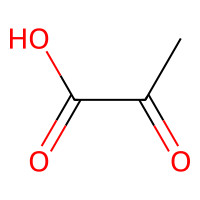
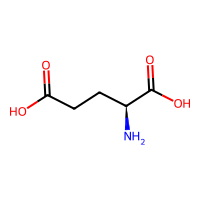
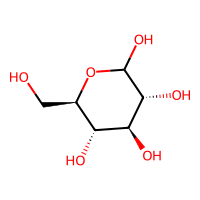
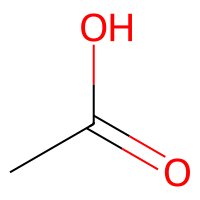
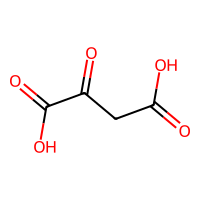
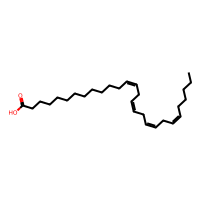
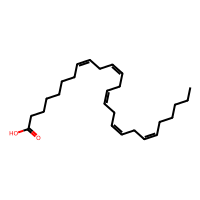
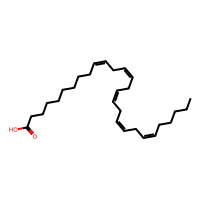
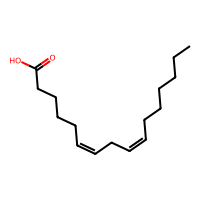
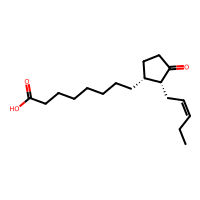

In [ ]:
df_BUL = pd.read_pickle('data/Database_NEWBUL.pkl')
df_BUL = df_BUL[df_BUL['BRITE'].str.contains('Monosaccharides|Amino acids|Fatty acyls', na=False)]
df_BUL['label'] = df_BUL['BRITE'].apply(lambda x:
    'Monosaccharides' if 'Monosaccharides' in x
    else 'Amino acids' if 'Amino acids' in x
    else 'Fatty acyls' if 'Fatty acyls' in x
    else 'other')

In [18]:
from bokeh_graph import bokeh_plot

# Convert mainl_label column to int if string
if df_BUL['label'].dtype == 'object':
    df_BUL['label'] = df_BUL['label'].astype('category')
    df_BUL['label'] = df_BUL['label'].cat.codes
df_BUL

bokeh_plot(df_BUL, "label", id_field="npaid",
           smiles_column='ISOSMILES')


Loading BokehJS ...

,ID,ISOSMILES,Formula,MW,InChI,BRITE,label,t-sne 1,t-sne 2
8,C00022,CC(=O)C(=O)O,C3H4O3,88.0621,"InChI=1S/C3H4O3/c1-2(4)3(5)6/h1H3,(H,5,6)",Compounds with biological roles [BR:br08001]\n...,1,-6.566303,-21.790806
10,C00025,N[C@@H](CCC(=O)O)C(=O)O,C5H9NO4,147.1293,"InChI=1S/C5H9NO4/c6-3(5(9)10)1-2-4(7)8/h3H,1-2...",Compounds with biological roles [BR:br08001]\n...,0,8.548512,-30.521223
14,C00031,OC[C@H]1OC(O)[C@H](O)[C@@H](O)[C@@H]1O,C6H12O6,180.1559,InChI=1S/C6H12O6/c7-1-2-3(8)4(9)5(10)6(11)12-2...,Compounds with biological roles [BR:br08001]\n...,2,-36.781197,45.118374
16,C00033,CC(=O)O,C2H4O2,60.0520,"InChI=1S/C2H4O2/c1-2(3)4/h1H3,(H,3,4)",Compounds with biological roles [BR:br08001]\n...,1,-16.233488,-17.346109
18,C00036,O=C(O)CC(=O)C(=O)O,C4H4O5,132.0716,"InChI=1S/C4H4O5/c5-2(4(8)9)1-3(6)7/h1H2,(H,6,7...",Compounds with biological roles [BR:br08001]\n...,1,9.223086,-15.246922
...,...,...,...,...,...,...,...,...,...
15685,C21962,CCCCC/C=C\C/C=C\C/C=C\C/C=C\CCCCCCCCCCCC(=O)O,C28H48O2,416.6795,InChI=1S/C28H48O2/c1-2-3-4-5-6-7-8-9-10-11-12-...,Lipids [BR:br08002]\n FA Fatty ac...,1,48.761471,29.268778
15686,C21964,CCCCC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCCCCC(=O)O,C26H42O2,386.6105,InChI=1S/C26H42O2/c1-2-3-4-5-6-7-8-9-10-11-12-...,Lipids [BR:br08002]\n FA Fatty ac...,1,46.361359,26.216959
15687,C21966,CCCCC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCCCCCCCC(=O)O,C28H46O2,414.6636,InChI=1S/C28H46O2/c1-2-3-4-5-6-7-8-9-10-11-12-...,Lipids [BR:br08002]\n FA Fatty ac...,1,46.361359,26.216959
15700,C21980,CCCCCC/C=C\C/C=C\CCCCC(=O)O,C16H28O2,252.3923,InChI=1S/C16H28O2/c1-2-3-4-5-6-7-8-9-10-11-12-...,Lipids [BR:br08002]\n FA Fatty ac...,1,43.957672,28.402866


In [14]:
df_BUL = pd.read_pickle('data/Database_NEWBUL.pkl')

df_UCL = pd.read_csv('data/Database_UCL.csv', keep_default_na=False).sample(3000)
PandasTools.AddMoleculeColumnToFrame(df_UCL, smilesCol='ISOSMILES')
df_UCL['MW'] = df_UCL['ROMol'].apply(lambda x: Chem.rdMolDescriptors.CalcExactMolWt(x))
df_UCL['MW'] = df_UCL['MW'].apply(lambda x: round(x, 3))
df_UCL['FP'] = df_UCL['ROMol'].apply(lambda x: Chem.RDKFingerprint(x, maxPath=7, minPath=1, fpSize=2048))
df_UCL[['Similar_KID', 'Similar_ISOSMILES']] = ['NA']*2

In [26]:
# xy = []
for c in range(110, 151, 10):
    n_sim = 0
    for i, row in tqdm(df_UCL.iterrows(), total=df_UCL.shape[0], desc=f'Calculating Similarity with c={c}'):
        df_aux = df_BUL[(df_BUL['MW'] - c <= row.MW) & (df_BUL['MW'] + c >= row.MW)]

        if len(df_aux) > 0:
            df_aux['similarity'] = df_aux['FP'].apply(lambda x: TanimotoSimilarity(x, row.FP))

            max = df_aux.loc[df_aux['similarity'].idxmax()]
            if max['similarity'] >= 0.6:
                n_sim += 1

    xy.append([c, n_sim])
    clear_output()
    print(xy)

[[10, 1166], [20, 1471], [30, 1587], [40, 1673], [50, 1733], [60, 1799], [70, 1837], [80, 1864], [90, 1898], [100, 1930], [110, 1943], [120, 1957], [130, 1972], [140, 1982], [150, 1995]]


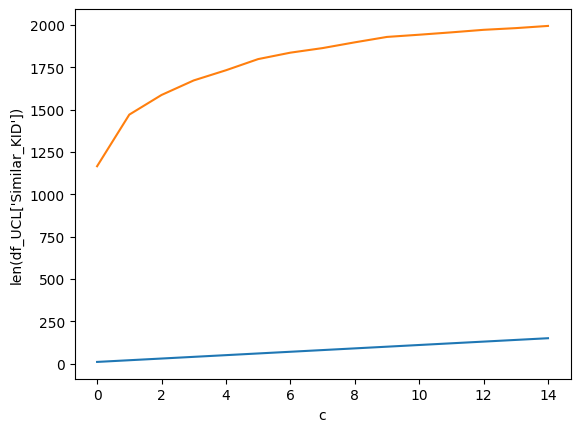

In [27]:
# use pyplot to plot len(df_UCL['Similar_KID'].dropna()) vs c
import matplotlib.pyplot as plt
import numpy as np

plt.plot(xy)
plt.xlabel('c')
plt.ylabel('len(df_UCL[\'Similar_KID\'])')
plt.show()
